# **Lab 8 : Edge Detection**

### **Student: Nawaf Rabea Shahbal - 2240009025**

## **Task 1: Apply Edge Detection Methods**
1. Select a new image (`Images/astronaut.jpg`).
2. Apply **Sobel**, **Prewitt**, and **Canny** edge detectors using the provided notebook as a reference.
3. Display the original image and the three resulting edge maps.

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, io

# Save and select a new image (different from Butterfly.jpg)
os.makedirs('Images', exist_ok=True)
imgFile = 'Images/astronaut.jpg'
if not os.path.exists(imgFile):
    io.imsave(imgFile, data.astronaut())

# Load the image
img = cv2.imread(imgFile)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print('Image shape:', img.shape)

Image shape: (512, 512, 3)


### **1. Sobel Edge Detector**

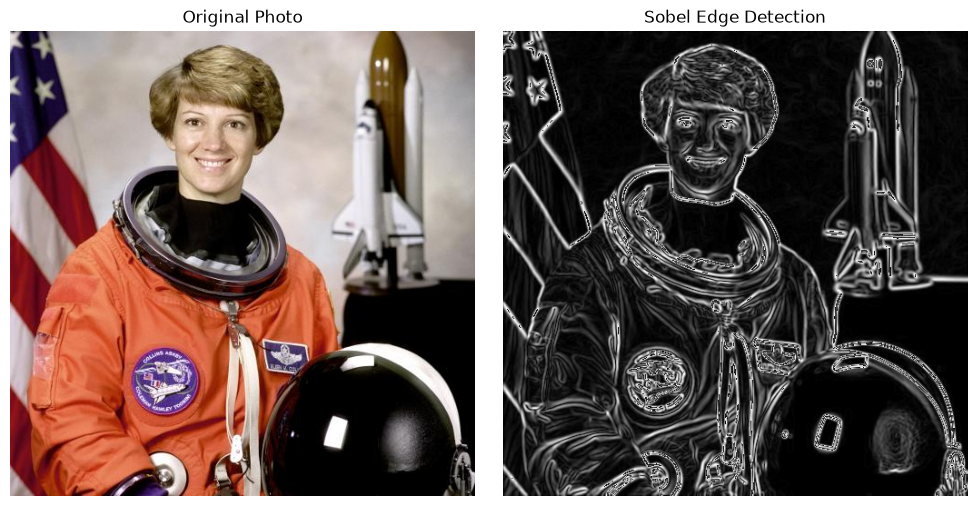

In [2]:
# 1. Load the real image
img = cv2.imread(imgFile)

# 2. Convert to Grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 3. Apply Gaussian Blur to reduce noise
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# 4. Apply Sobel filter
# cv2.CV_64F handles the high precision needed for derivatives
sobelx = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

# 5. Calculate Magnitude (Final Edge Map)
sobel_combined = cv2.magnitude(sobelx, sobely)

# 6. Normalize to 0-255 for display
sobel_final = np.uint8(np.absolute(sobel_combined))

# Visualization
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Photo'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(sobel_final, cmap='gray'), plt.title('Sobel Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

### **2. Prewitt Edge Detector**

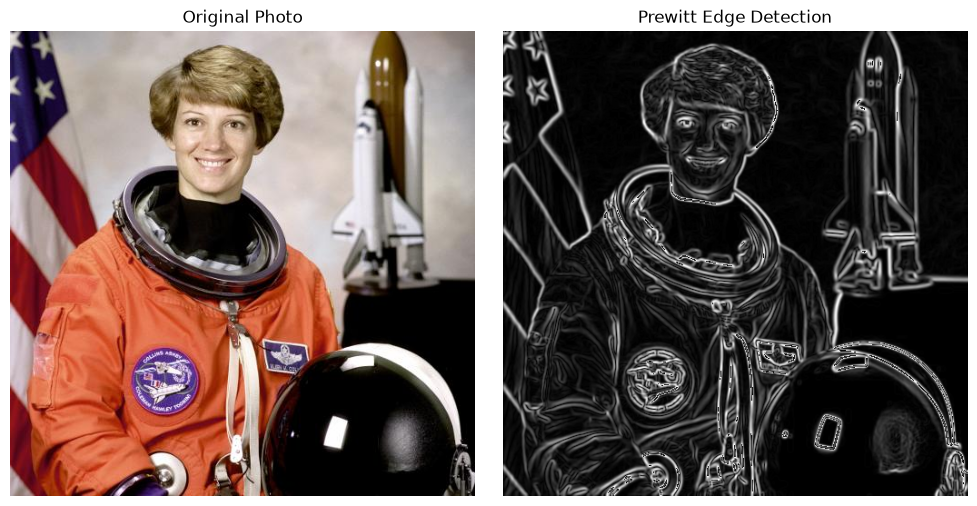

In [3]:
# 1. Load the real image
img = cv2.imread(imgFile)

# 2. Grayscale & Blur (Essential for real photos to reduce grain)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# 3. Define Prewitt Kernels manually
kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)

# 4. Apply filters
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, kernel_y)

# 5. Calculate Magnitude (Combine X and Y)
prewitt_combined = cv2.magnitude(prewitt_x, prewitt_y)

# 6. Normalize to 8-bit for display
prewitt_final = np.uint8(np.absolute(prewitt_combined))

# Visualizing results
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Photo'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(prewitt_final, cmap='gray'), plt.title('Prewitt Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

### **3. Canny Edge Detector**

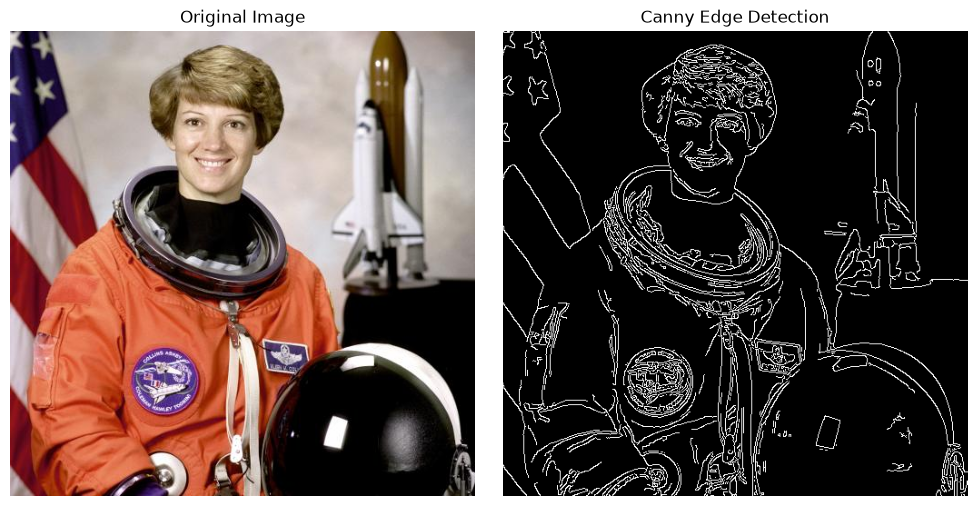

In [4]:
# 1. Load the real image
img = cv2.imread(imgFile)

# 2. Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 3. Apply Canny Edge Detection
# Syntax: cv2.Canny(image, low_threshold, high_threshold)
canny_edges = cv2.Canny(gray, 100, 200)

# 4. Visualization
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)), plt.title('Original Image'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(canny_edges, cmap='gray'), plt.title('Canny Edge Detection'), plt.axis('off')
plt.tight_layout()
plt.show()

### **Display the Original Image and the Three Resulting Edge Maps**

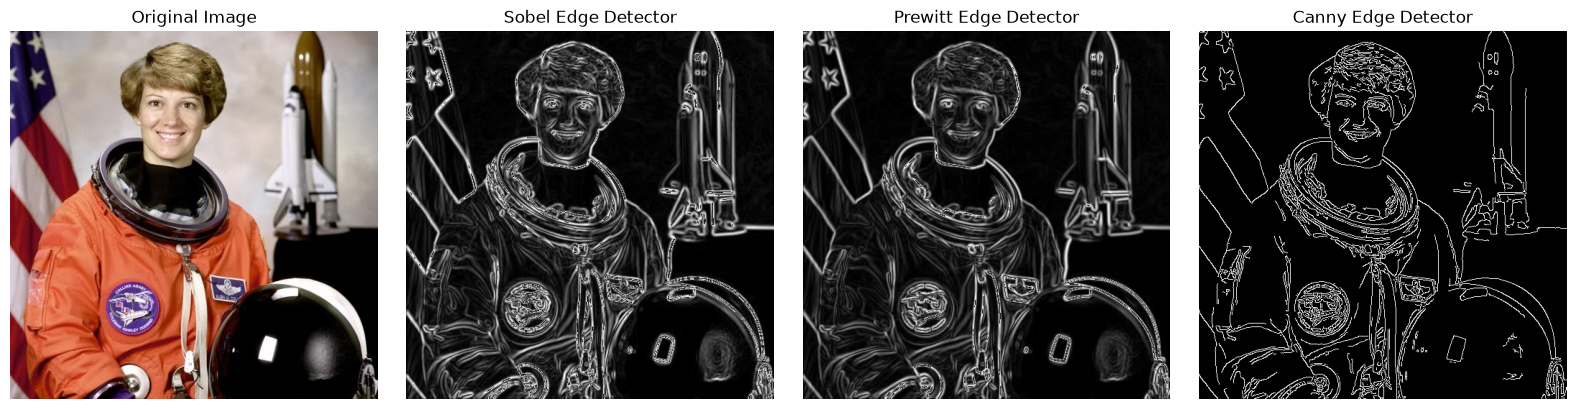

In [5]:
# Display the original image and the three resulting edge maps side by side
plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(sobel_final, cmap='gray')
plt.title('Sobel Edge Detector')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(prewitt_final, cmap='gray')
plt.title('Prewitt Edge Detector')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(canny_edges, cmap='gray')
plt.title('Canny Edge Detector')
plt.axis('off')

plt.tight_layout()
plt.show()

## **Task 2: Investigate the Effect of Canny Thresholds**
1. Apply Canny edge detection using the following threshold pairs:
   - Low = 30, High = 90
   - Low = 50, High = 150
   - Low = 100, High = 200
2. Display the three resulting edge maps side by side.
3. Explain how changing the thresholds affects the number of detected edges and the visibility of image details.

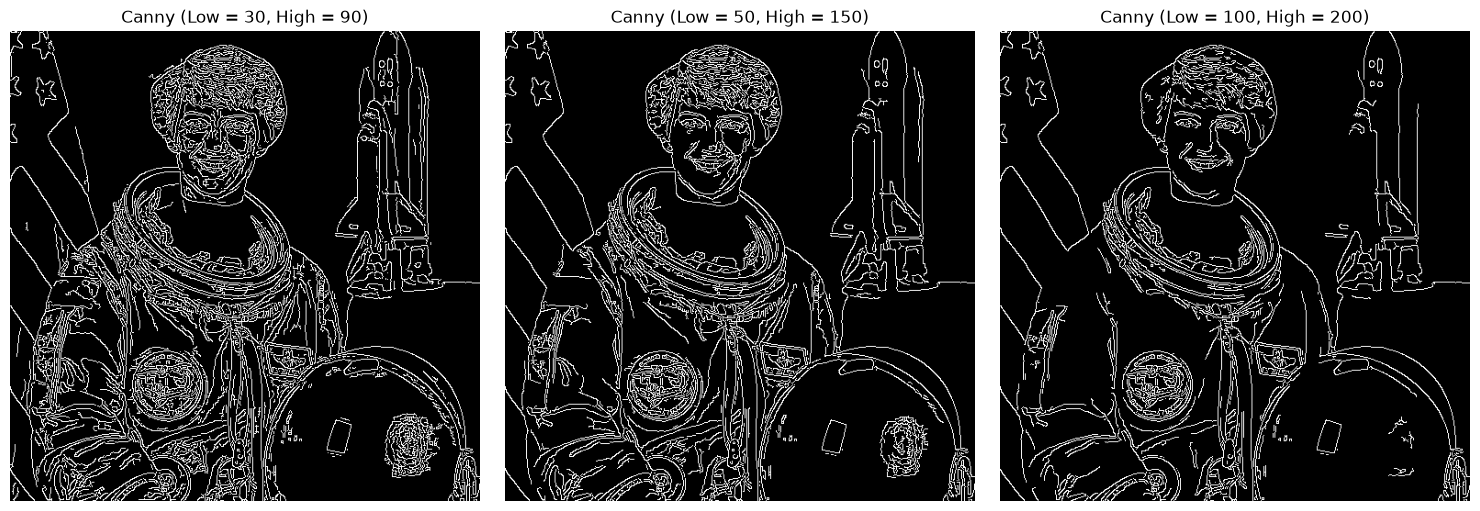

In [6]:
# 1. Apply Canny edge detection with the three threshold pairs
canny_30_90 = cv2.Canny(gray, 30, 90)
canny_50_150 = cv2.Canny(gray, 50, 150)
canny_100_200 = cv2.Canny(gray, 100, 200)

# 2. Display the three resulting edge maps side by side
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(canny_30_90, cmap='gray')
plt.title('Canny (Low = 30, High = 90)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(canny_50_150, cmap='gray')
plt.title('Canny (Low = 50, High = 150)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(canny_100_200, cmap='gray')
plt.title('Canny (Low = 100, High = 200)')
plt.axis('off')

plt.tight_layout()
plt.show()

### **Explanation: Effect of Canny Thresholds**

- **Low = 30, High = 90:** With lower thresholds, even weak intensity gradients are accepted as edges. This results in the **highest number of detected edges** and makes fine textures and small details very visible (such as facial features, hair strands, and small suit details), but it also picks up more unwanted background noise and minor texture variations.
- **Low = 50, High = 150:** Increasing the thresholds removes many of the weak noise edges while preserving most of the important structural edges. It provides a good balance between noise reduction and detail visibility.
- **Low = 100, High = 200:** With higher thresholds, only pixels with strong intensity changes exceed the upper threshold. As a result, the **number of detected edges decreases significantly**, and faint details or subtle textures disappear, leaving only the sharpest, most prominent boundaries and main outlines of the image.